In [64]:
import sys
if "../" not in sys.path:
    sys.path.append("../")
    
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.wong import sigma
from src.plot import plot_D_f
#from src.utils import compute_peak_metrics

import scienceplots
plt.style.use(['science', 'no-latex', 'ieee'])

import scipy as sp
import os
from scipy.optimize import curve_fit
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern, ConstantKernel, ExpSineSquared, RationalQuadratic
import findiff as fd



plt.rc('xtick', labelsize=24)
plt.rc('ytick', labelsize=24)
plt.rc('axes', labelsize=24) 
plt.rc('legend', fontsize=24)    # all future legends will be 14-pt

save_data = True # Toggle to True to overrwite training data

<>:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/ipykernel_3224433/1611761327.py:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  tmpdf = pd.read_csv(os.path.join(dirname,file),sep='\s+',names=['Ecm','Sigma','Error'])


Best-fit parameters:
  E0    = 73.3846 ± 0.0047 MeV
  R0    = 10.2260 ± 0.0078 fm
  hbarw = 4.8410 ± 0.0074 MeV


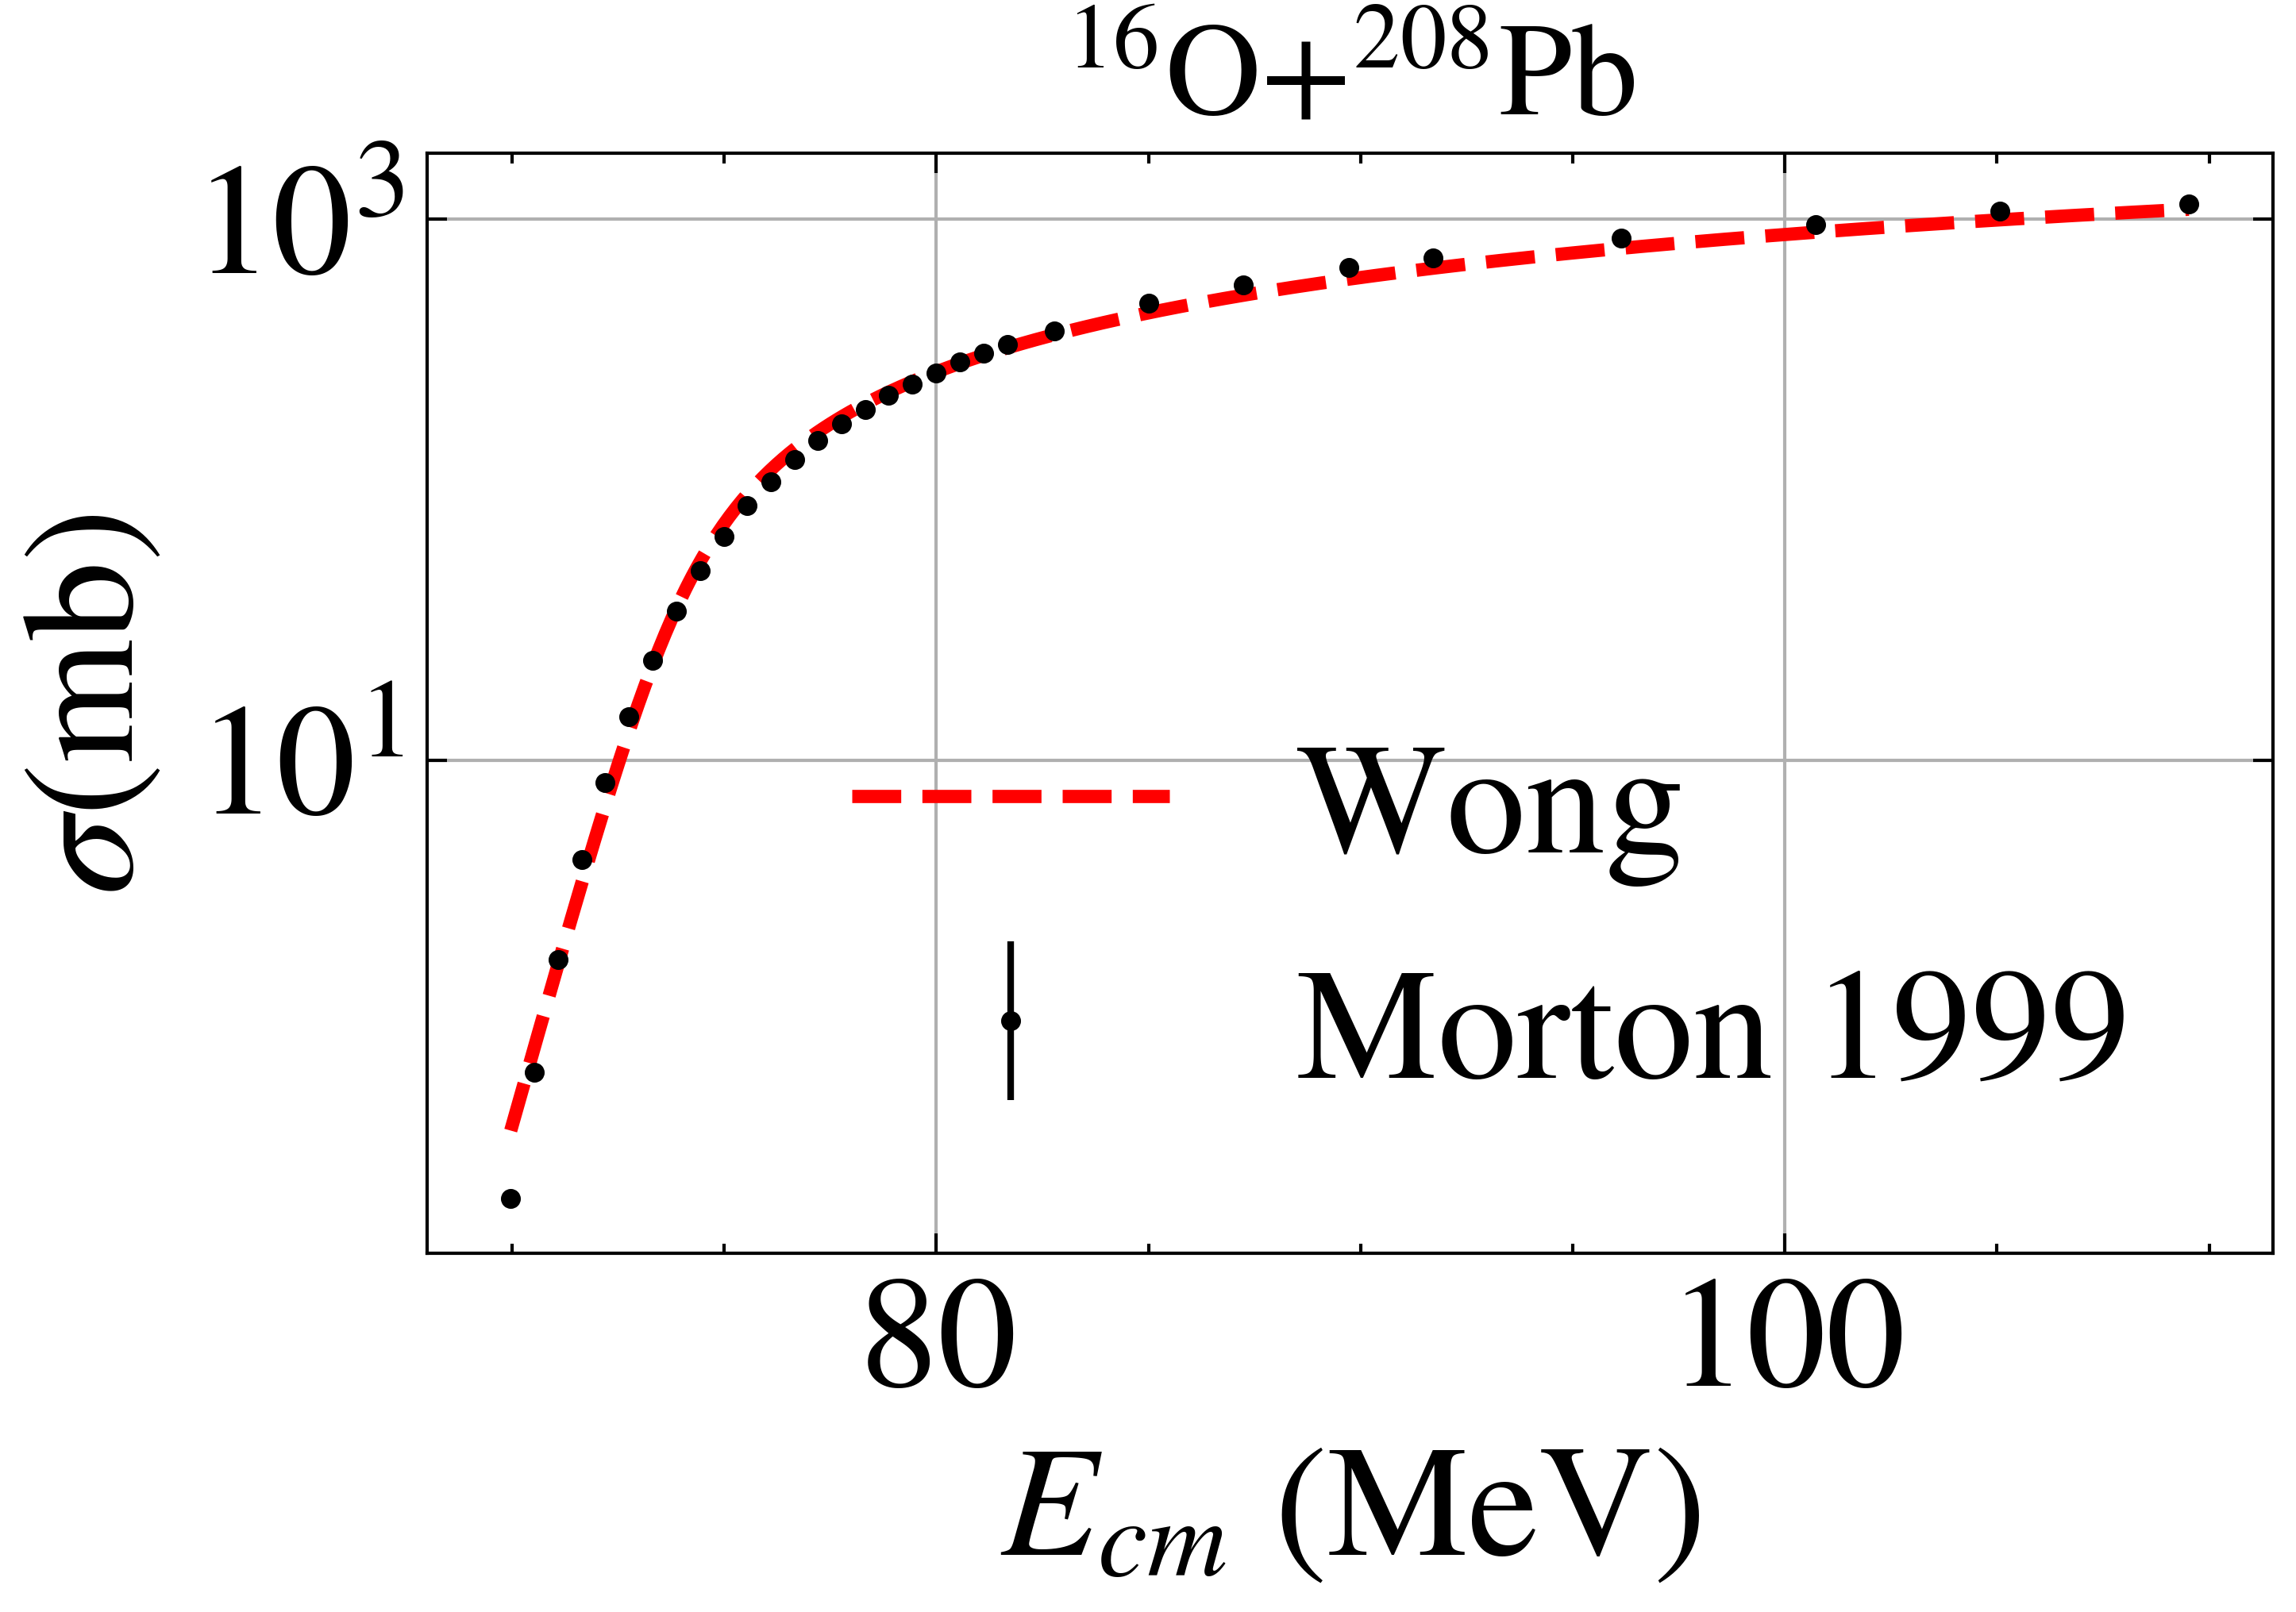

In [65]:
dirname = "../../barrier-distribution-sample/16O208Pb_exp"
system = "$^{208}$Pb+$^{16}$O"
fileprefix = dirname

expfiles = [ 'expMort.dat', 'expDas.dat' ]
explabel = [ 'Morton et al. 1999', 'Dasgupta et al. 2007' ]
expmarker = [ 'o', 's' ]
expcolor = [ 'k', 'g' ]

exp = []

for file in expfiles:
    tmpdf = pd.read_csv(os.path.join(dirname,file),sep='\s+',names=['Ecm','Sigma','Error'])
    if(tmpdf['Ecm'].iloc[0] > tmpdf['Ecm'].iloc[-1]):
        exp.append(tmpdf.iloc[::-1])
    else:
        exp.append(tmpdf)

xmin = 70.0
xmax = 90.0


E_data = exp[0]['Ecm'].to_numpy()
Sigma_data = exp[0]['Sigma'].to_numpy()
Sigma_err  = exp[0]['Error'].to_numpy()


# --- Initial guesses for [E0, R0, hbarw] ---
# You may need to tweak these based on your system.
initial_guess = [70.0, 11.0, 4]  # e.g. E0≈10MeV, R0≈7fm, ħω≈4MeV

# --- Perform the fit ---
popt, pcov = curve_fit(
    sigma,
    E_data,
    Sigma_data,
    p0=initial_guess,
    sigma=Sigma_err,
    absolute_sigma=True,
    # bounds can help keep parameters physical:
    bounds=([0.0, 8.0, 0.0], [np.inf, 15.0, np.inf])
)

E0_opt, R0_opt, hbarw_opt = popt
perr = np.sqrt(np.diag(pcov))

print(f"Best-fit parameters:")
print(f"  E0    = {E0_opt:.4f} ± {perr[0]:.4f} MeV")
print(f"  R0    = {R0_opt:.4f} ± {perr[1]:.4f} fm")
print(f"  hbarw = {hbarw_opt:.4f} ± {perr[2]:.4f} MeV")

# --- Plot experiment vs. fit ---
E_plot = np.linspace(E_data.min(), E_data.max(), 500)
Sigma_fit = sigma(E_plot, E0_opt, R0_opt, hbarw_opt)

plt.figure(figsize=(5,3))
plt.errorbar(E_data, Sigma_data, yerr=Sigma_err, fmt='o', label='Morton 1999', markersize=2)
#plt.scatter(E_data, Sigma_data, label='Morton 1999', color='k', s=10)
plt.plot(E_plot, Sigma_fit, label='Wong', linewidth=2)
plt.xlabel(r'$E_{cm}$ (MeV)')
plt.ylabel(r'$\sigma$(mb)')
plt.title("$^{16}$O+$^{208}$Pb")
plt.yscale('log')
plt.legend()
plt.grid(True)
#plt.tight_layout()
plt.show()

In [66]:
#from src.train import train_gp
from src.plot import plot_gp_with_data
from src.utils import barrier_dist, point_diff

def train_gp(E_train, sigma_mu_train, sigma_var_train, n_restarts=20, kernel=None, noise=None, log=False):
    """
    Train a Gaussian Process on 1D data with heteroscedastic noise.

    Parameters
    ----------
    E_train : array-like, shape (N,)
        Training energies.
    sigma_mu_train : array-like, shape (N,)
        Mean cross-section values at E_train.
    delta_sigma_train : array-like, shape (N,)
        Variance of cross-section at E_train (i.e., noise variances).
    n_restarts : int, optional (default=10)
        Number of restarts for the optimizer.

    Returns
    -------
    gp : GaussianProcessRegressor
        The fitted GP model.
    """
    # 1) Sort E_train for length-scale estimation
    E_sorted = np.sort(np.asarray(E_train))
    dE = np.diff(E_sorted)
    ell0 = min(np.abs(dE))
    lbound, ubound = ell0 , 10.0

    # 2) Compute signal variance from the training mean
    var_y0 = np.var(sigma_mu_train)
    print(var_y0)

    if kernel is None:
        # 3) Build kernel: Constant * RBF  + WhiteKernel
        k_rbf   = 1.0*RBF(length_scale=1.0, length_scale_bounds=(lbound, ubound))#ConstantKernel() length_scale_bounds=(lbound, ubound)) # *ConstantKernel(constant_value=var_y0, constant_value_bounds=(var_y0/100, var_y0*100)) 
        kernel  = k_rbf
        if noise: 
            k_noise = WhiteKernel(noise_level=1e-5 , noise_level_bounds=(1e-9, 1e-3))
            kernel  += k_noise

    if log: 
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha= sigma_var_train / sigma_mu_train**2,
            normalize_y=False,
            n_restarts_optimizer=n_restarts
        )
        gp.fit(np.asarray(E_train).reshape(-1, 1), np.log(np.asarray(sigma_mu_train)))
    else:
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha=sigma_var_train,
            normalize_y=False,
            n_restarts_optimizer=n_restarts
        )
        gp.fit(np.asarray(E_train).reshape(-1, 1), np.asarray(sigma_mu_train))

    return gp

# ---------- Residual summary table ----------
def summarize(err):
    if err.size == 0:
        return dict(n=0, mean=np.nan, std=np.nan, median=np.nan, MAE=np.nan, RMSE=np.nan,
                    min=np.nan, max=np.nan)
    return dict(
        n      = int(err.size),
        mean   = float(np.mean(err)),
        std    = float(np.std(err, ddof=1)) if err.size > 1 else 0.0,
        median = float(np.median(err)),
        MAE    = float(np.mean(np.abs(err))),
        RMSE   = float(np.sqrt(np.mean(err**2))),
        min    = float(np.min(err)),
        max    = float(np.max(err)),
    )

def symmetric_bins(err, bins=30, clip_percentiles=(1, 99)):
    """Symmetric bin edges around 0 using robust percentiles."""
    if err.size == 0:
        return np.linspace(-1, 1, bins + 1)
    lo, hi = np.percentile(err, clip_percentiles)
    rng = max(abs(lo), abs(hi), 1e-12)
    return np.linspace(-rng, rng, bins + 1)

# ---------- LaTeX figure helpers ----------
TRUE_COLOR = "tab:blue"
GP_COLOR = "tab:green"
DATA_COLOR = "0.15"
BAND_ALPHA = 0.22
DATA_BAND_ALPHA = 0.10
SHARED_LABEL_FONTSIZE = 24
SHARED_XLABEL_Y = 0.06
SHARED_YLABEL_X = 0.1


def format_eta(ratio):
    e = int(np.floor(np.log10(ratio)))
    m = ratio / 10**e
    if np.isclose(m, 1.0):
        return rf"$\eta = 10^{{{e}}}$"
    return rf"$\eta = {m:.1f}\times 10^{{{e}}}$"


def add_panel_label(ax, label):
    ax.text(
        0.03,
        0.92,
        label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.5),
    )


def sigma_barrier_legend_handles():
    handles = [
        plt.Line2D([], [], color=TRUE_COLOR, lw=2.0, label="True"),
        plt.Line2D([], [], color=GP_COLOR, lw=2.0, ls="--", label="GP mean"),
        plt.Rectangle((0, 0), 1, 1, color=GP_COLOR, alpha=BAND_ALPHA, label="GP 95% CI"),
        plt.Line2D([], [], marker="o", color=DATA_COLOR, lw=0, markersize=4, label="Train pts"),
    ]
    return handles



def barrier_legend_handles():
    return [
        plt.Line2D([], [], color=TRUE_COLOR, lw=2.0, label="True"),
        plt.Line2D([], [], color=GP_COLOR, lw=2.0, ls="--", label="GP mean"),
        plt.Rectangle((0, 0), 1, 1, color=GP_COLOR, alpha=BAND_ALPHA, label="GP 95% CI"),
        plt.Line2D([], [], marker="o", color=DATA_COLOR, lw=0, markersize=4, label="Train pts"),
    ]


def add_inset_legend(ax, handles, ncol=1):
    ax.legend(
        handles=handles,
        loc="upper right",
        bbox_to_anchor=(0.98, 0.98),
        bbox_transform=ax.transAxes,
        ncol=ncol,
        frameon=True,
        framealpha=0.88,
        facecolor="white",
        edgecolor="0.75",
        fontsize=8,
        handlelength=1.6,
        borderpad=0.35,
        labelspacing=0.3,
        columnspacing=0.8,
    )


def plot_sigma_barrier_grid(results_dict, outfile, suptitle=None):
    items = list(results_dict.items())[:8]
    nrows, ncols = len(items), 2
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.2, 2.35 * nrows), sharex="col")
    axes = np.asarray(axes).reshape(nrows, ncols)
    y_true_sigma = sigma(E_eval, E0_opt, R0_opt, hbarw_opt)

    for row, (_, data) in enumerate(items):
        E_train_local = data.get("E_train", E_train)
        mu = data["mu"]
        std = data["std"]
        samples = data["samples"]
        ratio = data["ratio"]
        alpha = data.get("alpha")
        sigma_train_noisy = data.get("sigma_train_noisy", sigma_train)
        row_label = format_eta(ratio)

        ax_sigma = axes[row, 0]
        ax_barrier = axes[row, 1]

        ax_sigma.plot(E_eval, y_true_sigma, lw=2.0, color=TRUE_COLOR)
        ax_sigma.plot(E_eval, mu, lw=2.0, ls="--", color=GP_COLOR)
        ax_sigma.fill_between(E_eval, mu - 1.96 * std, mu + 1.96 * std, color=GP_COLOR, alpha=BAND_ALPHA, linewidth=0)
        ax_sigma.scatter(E_train_local, sigma_train_noisy, s=8, color=DATA_COLOR, alpha=0.8, edgecolor="none", zorder=5)
        add_panel_label(ax_sigma, row_label)
        ax_sigma.set_xlim(E_eval[0], E_eval[-1])
        ax_sigma.tick_params(labelsize=9)

        barrier_E = data.get("barrier_E", E_fine)
        ax_barrier.plot(E_fine, true_d, lw=2.0, color=TRUE_COLOR)
        d_samples = np.stack([barrier_dist(barrier_E, samples[:, j], acc=4) for j in range(samples.shape[1])], axis=1)
        d_mu = d_samples.mean(axis=1)
        d_std = d_samples.std(axis=1)
        true_d_train = np.interp(E_train_local, E_fine, true_d)
        ax_barrier.plot(barrier_E, d_mu, lw=2.0, ls="--", color=GP_COLOR)
        ax_barrier.fill_between(barrier_E, d_mu - 1.96 * d_std, d_mu + 1.96 * d_std, color=GP_COLOR, alpha=BAND_ALPHA, linewidth=0)
        ax_barrier.scatter(E_train_local, true_d_train, s=8, color=DATA_COLOR, alpha=0.8, edgecolor="none", zorder=5)
        add_panel_label(ax_barrier, row_label)
        ax_barrier.set_xlim(E_train_local[0] - 5, E_train_local[-1] + 5)
        ax_barrier.set_ylim(np.min(true_d) - 200, np.max(true_d) + 500)
        ax_barrier.tick_params(labelsize=9)

    axes[0, 0].set_title(r"Cross section $\sigma(E)$", fontsize=12)
    axes[0, 1].set_title(r"Barrier distribution $D_f(E)$", fontsize=12)

    if suptitle:
        fig.suptitle(suptitle, fontsize=12, y=0.995)
    add_inset_legend(axes[0, 1], sigma_barrier_legend_handles())
    fig.tight_layout(rect=[0.045, 0.09, 1, 0.965 if suptitle else 0.99])
    fig.subplots_adjust(wspace=0.18)
    left = axes[-1, 0].get_position().x0
    right = axes[-1, -1].get_position().x1
    fig.text(0.5 * (left + right), SHARED_XLABEL_Y, r"$E_{\mathrm{cm}}$ (MeV)", ha="center", va="center", fontsize=SHARED_LABEL_FONTSIZE)
    fig.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def plot_barrier_grid(results_dict, outfile, panel_title_fn, e_dist_getter=None, ncols=2, suptitle=None):
    items = list(results_dict.items())
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.2, 2.7 * nrows), sharex=True, sharey=True)
    axes = np.asarray(axes).reshape(nrows, ncols)

    for ax, (key, data) in zip(axes.ravel(), items):
        E_tr = data["E_tr"]
        samples = data["samples"]
        E_dist_local = e_dist_getter(key, data) if e_dist_getter else data["E_dist"]
        true_d_train = np.interp(E_tr, E_fine, true_d)
        d_samples = np.vstack([barrier_dist(E_dist_local, samples[:, j], acc=4) for j in range(samples.shape[1])])
        d_mu = d_samples.mean(axis=0)
        d_std = d_samples.std(axis=0)

        ax.plot(E_fine, true_d, lw=2.0, color=TRUE_COLOR, label="True")
        ax.plot(E_dist_local, d_mu, lw=2.0, ls="--", color=GP_COLOR, label="GP mean")
        ax.fill_between(
            E_dist_local,
            d_mu - 1.96 * d_std,
            d_mu + 1.96 * d_std,
            color=GP_COLOR,
            alpha=BAND_ALPHA,
            linewidth=0,
            label="GP 95% CI",
        )
        ax.scatter(E_tr, true_d_train, s=10, color=DATA_COLOR, edgecolor="none", zorder=5, label="Train pts")
        add_panel_label(ax, panel_title_fn(key, data))
        ax.set_xlim(E_tr[0], 90)
        ax.set_ylim(-1000, 1500)
        ax.tick_params(labelsize=9)

    for ax in axes.ravel()[len(items):]:
        ax.set_visible(False)
    fig.supxlabel(r"$E_{\mathrm{cm}}$ (MeV)", fontsize=SHARED_LABEL_FONTSIZE, y=SHARED_XLABEL_Y)
    fig.supylabel(r"$D_f(E)$ (mb/MeV)", fontsize=SHARED_LABEL_FONTSIZE, x=SHARED_YLABEL_X)

    if suptitle:
        fig.suptitle(suptitle, fontsize=12, y=0.995)
    add_inset_legend(axes[0, -1], barrier_legend_handles())
    fig.tight_layout(rect=[0.06, 0.09, 1, 0.965 if suptitle else 0.99])
    fig.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def plot_barrier_comparison_grid(column_specs, outfile, row_keys, panel_label_fn, suptitle=None):
    nrows, ncols = len(row_keys), len(column_specs)
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.2, 2.35 * nrows), sharex=True, sharey=True)
    axes = np.asarray(axes).reshape(nrows, ncols)

    for col, spec in enumerate(column_specs):
        title, results_dict, e_dist_getter = spec
        axes[0, col].set_title(title, fontsize=12)
        for row, key in enumerate(row_keys):
            ax = axes[row, col]
            data = results_dict[key]
            E_tr = data["E_tr"]
            samples = data["samples"]
            E_dist_local = e_dist_getter(key, data) if e_dist_getter else data["E_dist"]
            true_d_train = np.interp(E_tr, E_fine, true_d)
            d_samples = np.vstack([barrier_dist(E_dist_local, samples[:, j], acc=4) for j in range(samples.shape[1])])
            d_mu = d_samples.mean(axis=0)
            d_std = d_samples.std(axis=0)

            ax.plot(E_fine, true_d, lw=2.0, color=TRUE_COLOR)
            ax.plot(E_dist_local, d_mu, lw=2.0, ls="--", color=GP_COLOR)
            ax.fill_between(E_dist_local, d_mu - 1.96 * d_std, d_mu + 1.96 * d_std, color=GP_COLOR, alpha=BAND_ALPHA, linewidth=0)
            ax.scatter(E_tr, true_d_train, s=9, color=DATA_COLOR, alpha=0.8, edgecolor="none", zorder=5)
            add_panel_label(ax, panel_label_fn(key, data))
            ax.set_xlim(E_tr[0], 90)
            ax.set_ylim(-1000, 1500)
            ax.tick_params(labelsize=9)

    if suptitle:
        fig.suptitle(suptitle, fontsize=12, y=0.995)
    fig.supylabel(r"$D_f(E)$ (mb/MeV)", fontsize=SHARED_LABEL_FONTSIZE, x=SHARED_YLABEL_X)
    add_inset_legend(axes[0, -1], barrier_legend_handles())
    fig.tight_layout(rect=[0.06, 0.09, 1, 0.965 if suptitle else 0.99])
    left = axes[-1, 0].get_position().x0
    right = axes[-1, -1].get_position().x1
    fig.text(0.5 * (left + right), SHARED_XLABEL_Y, r"$E_{\mathrm{cm}}$ (MeV)", ha="center", va="center", fontsize=SHARED_LABEL_FONTSIZE)
    fig.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)




In [67]:
# FINE GRID THAT WE NOW INVESTIGATE CORRUPTING
N = 1000
total_E = np.concatenate((exp[0]['Ecm'].to_numpy(), exp[1]['Ecm'].to_numpy()))
E_fine = np.linspace(total_E.min(), total_E.max(), N)
sigma_mean = sigma(E_fine, E0_opt, R0_opt, hbarw_opt )
E_eval   = np.linspace(E_fine.min() - 5, E_fine.max() + 5, 500)
n_samples = 40
gp_n_restarts = 2

# Training grid for Experiments 1/2; derivatives/reference curves stay on E_fine.
E_train_exp12 = np.arange(E_fine.min(), E_fine.max() + 1e-9, 0.2)
sigma_train_exp12 = sigma(E_train_exp12, E0_opt, R0_opt, hbarw_opt)

# PRECOMPUTE TRUE D_f(E) ON THE FINE GRID
true_d = barrier_dist(
    E_fine,
    sigma(E_fine, E0_opt, R0_opt, hbarw_opt),
    acc=4
)


### Experiment 1: Effect of Different Noise Levels

In [ ]:
# RNG for reproducible corruption
rng = np.random.default_rng(0)

# Experiment 1/2: train on a 0.2 MeV grid; true derivatives stay on E_fine.
noise_ratio = [5e-3, 1e-2, 5e-2, 1e-1]#[1e-16, 1e-8, 1e-4, 1e-2]
for ratio in noise_ratio:
    alpha = (ratio * sigma_train_exp12)**2
    sigma_noisy = sigma_train_exp12 + rng.normal(0, np.sqrt(alpha))

    # use ratio in filename (e.g. 0.005 -> "0.005")
    tag = f"{ratio:.3f}"
    if save_data:
        np.save(f"../data/E_train_exp12_{tag}.npy", E_train_exp12)
        np.save(f"../data/alpha_exp12_{tag}.npy", alpha)
        np.save(f"../data/sigma_train_noisy_exp12_{tag}.npy", sigma_noisy)


In [69]:
# PARAMETERS & GRIDS
noise_ratio = [5e-3, 1e-2, 5e-2, 1e-1]#[1e-16, 1e-8, 1e-4, 1e-2]
start = 0

# Create a 0.2 MeV training set for the GP:
E_train = E_train_exp12
sigma_train = sigma_train_exp12
rng = np.random.default_rng(0)

# TRAIN & PREDICT — store in a dict for plotting
results = {}
for i, ratio in enumerate(noise_ratio):
    alpha = (ratio * sigma_train)**2
    sigma_train_noisy = sigma_train + rng.normal(0, np.sqrt(alpha))
    gp = train_gp(E_train, sigma_train_noisy, alpha, n_restarts=gp_n_restarts)
    mu, std = gp.predict(E_eval.reshape(-1, 1), return_std=True)
    samples = gp.sample_y(E_fine.reshape(-1, 1), n_samples=n_samples)
    results[i] = {
        "gp": gp,
        "mu": mu,
        "std": std,
        "samples": samples,
        "barrier_E": E_fine,
        "ratio": ratio,
        "alpha": alpha,
        "E_train": E_train,
        "sigma_train_noisy": sigma_train_noisy,
    }


132331.47660503673


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 8 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


132700.49421302878


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 10 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 12 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 5 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html


132598.7310651272


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 6 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 10 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better v

135161.93342462412


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 10 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 8 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better v

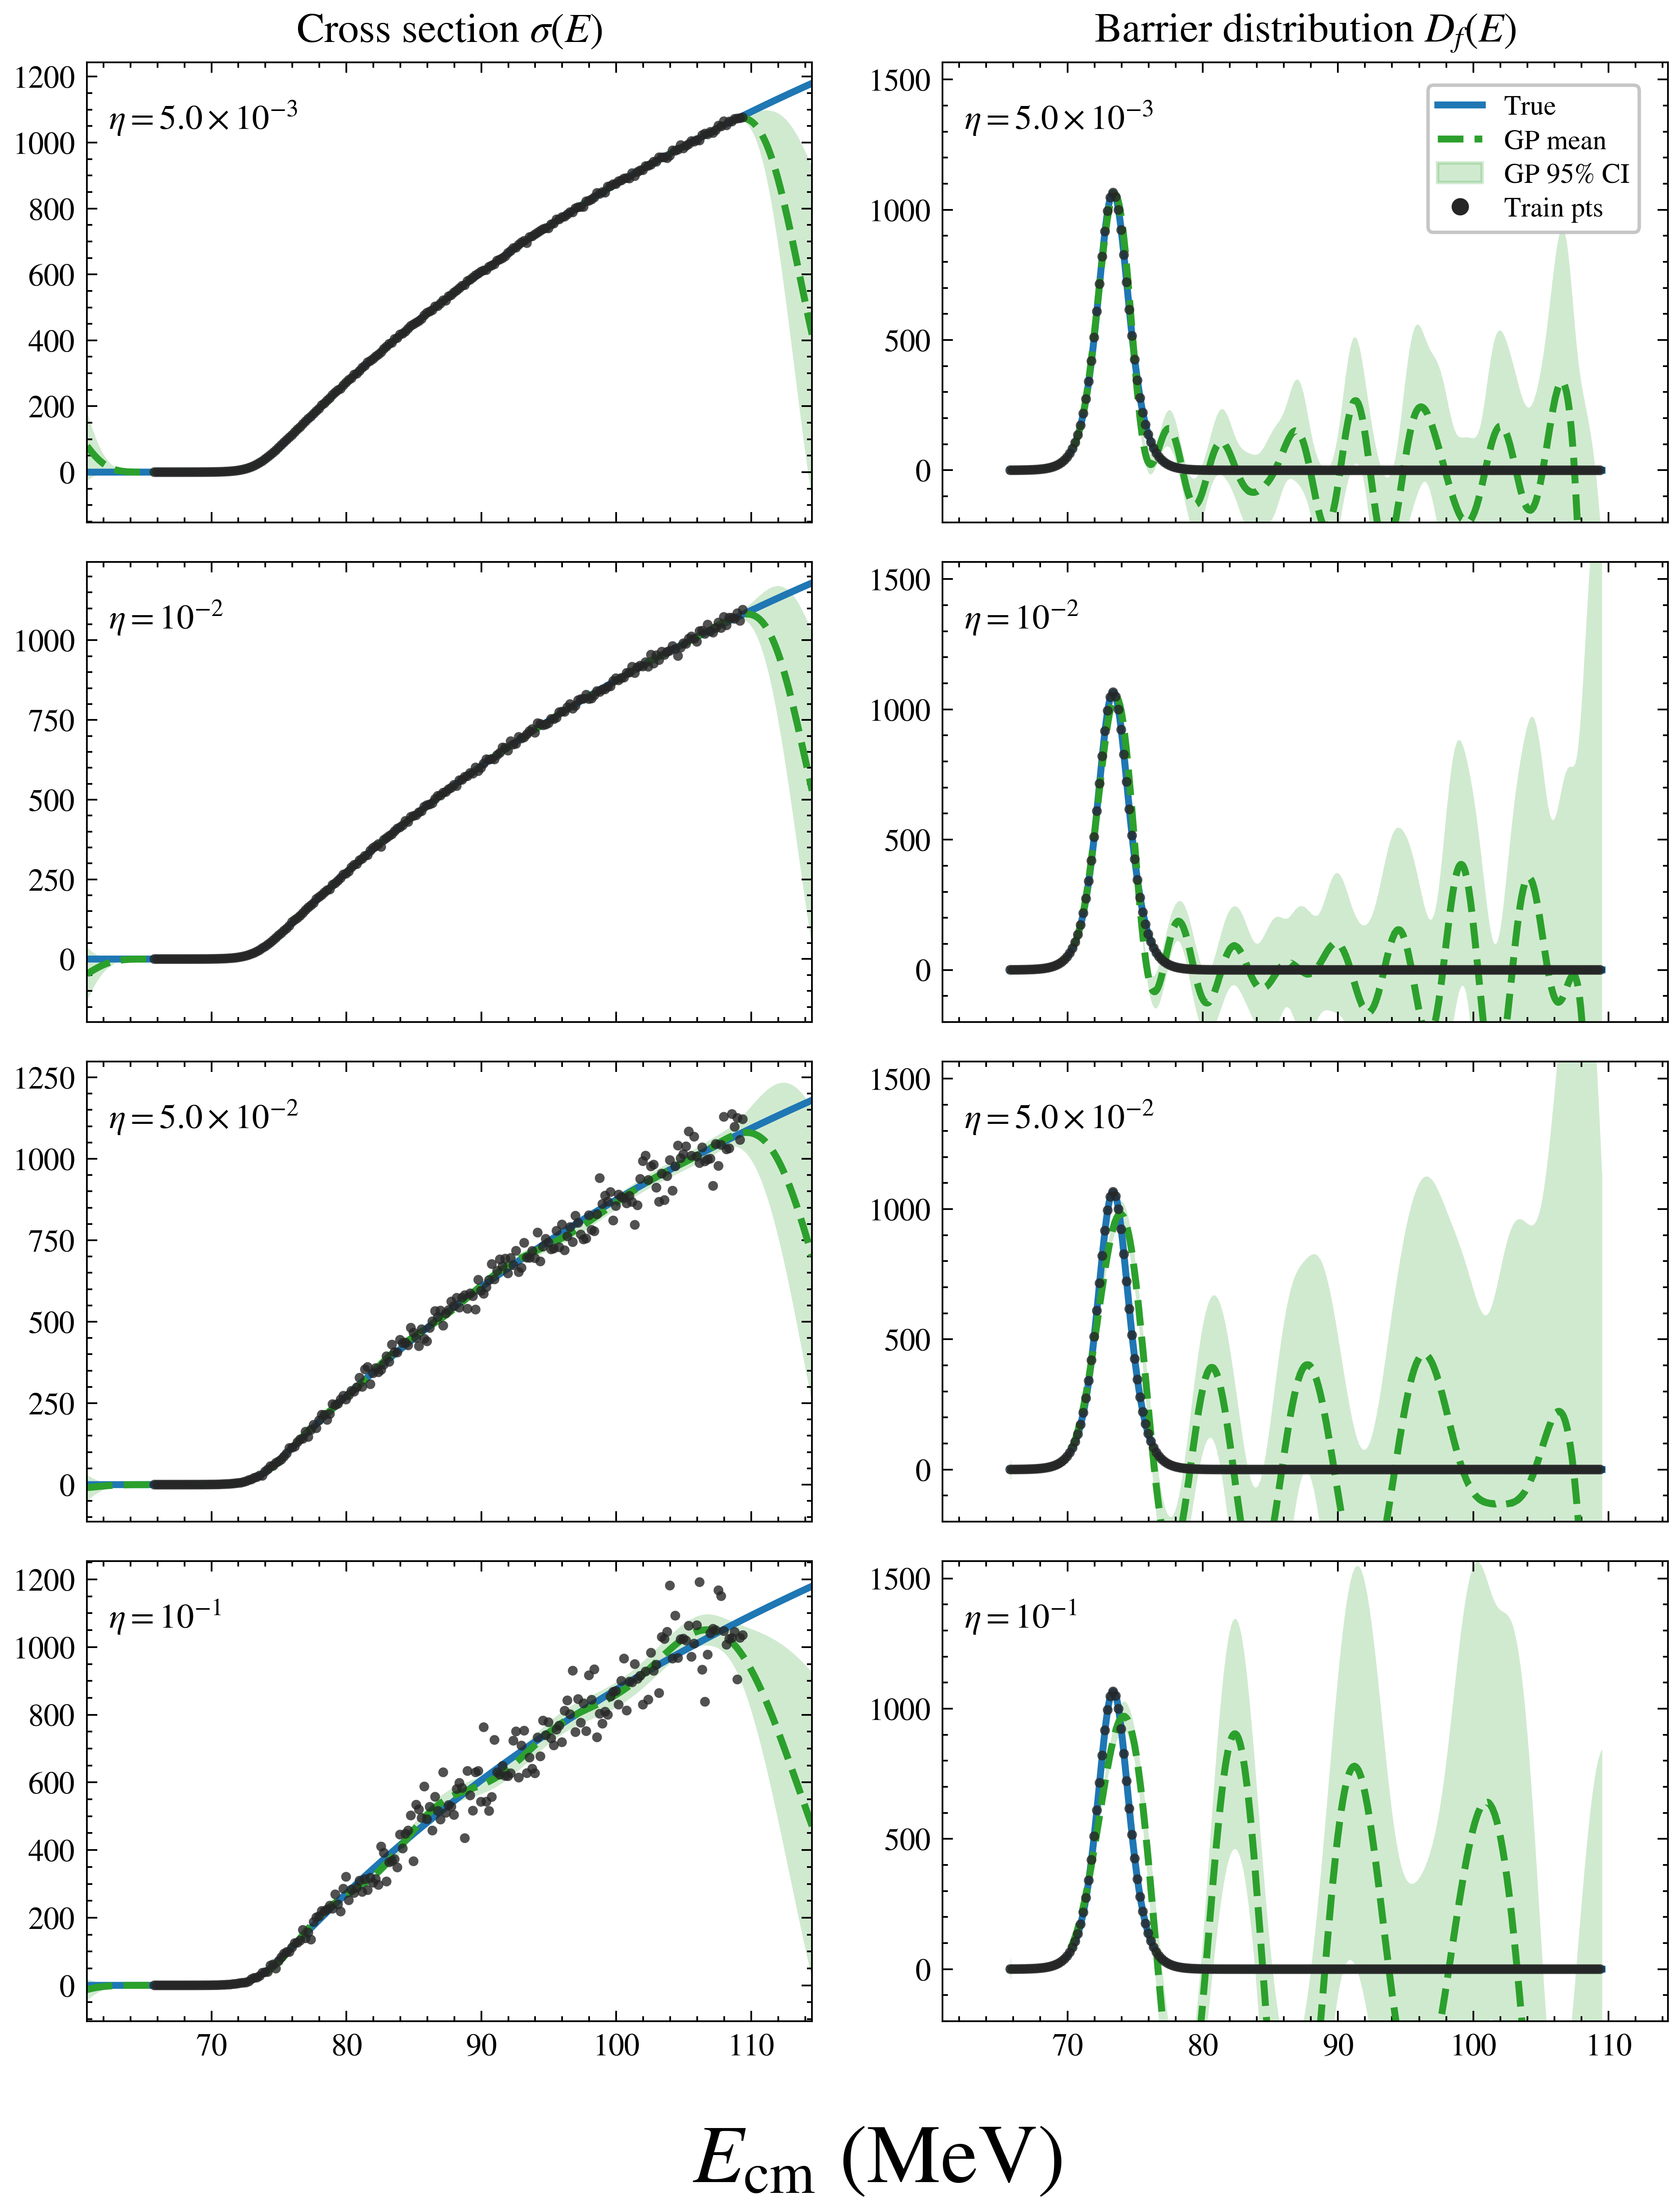

In [70]:
plot_sigma_barrier_grid(
    results,
    "../plots/gp_sigma_and_barrier_grid.png",
    suptitle=None,
)


In [71]:
# This used to save a duplicate of ../plots/gp_sigma_and_barrier_grid.png under
# ../plots/gp_sigma_and_barrier_grid_legacy_replacement.png. It adds no new
# content, so the duplicate export is intentionally disabled.


### Experiment 2: Effect of White Noise Kernel

In [72]:
# Create the same 0.2 MeV training set for the GP:
E_train = E_train_exp12
sigma_train = sigma_train_exp12
rng = np.random.default_rng(0)

# TRAIN & PREDICT — store in a dict for plotting
results_noise = {}
for i, ratio in enumerate(noise_ratio):
    alpha = (ratio * sigma_train)**2
    sigma_train_noisy = sigma_train + rng.normal(0, np.sqrt(alpha))
    gp = train_gp(E_train, sigma_train_noisy, alpha, n_restarts=gp_n_restarts, noise=True)
    mu, std = gp.predict(E_eval.reshape(-1, 1), return_std=True)
    samples = gp.sample_y(E_fine.reshape(-1, 1), n_samples=n_samples)
    exponent = int(np.log10(ratio))
    results_noise[i] = {
        "gp": gp,
        "mu": mu,
        "std": std,
        "samples": samples,
        "barrier_E": E_fine,
        "exp": exponent,
        "ratio": ratio,
        "alpha": alpha,
        "E_train": E_train,
        "sigma_train_noisy": sigma_train_noisy,
    }


132331.47660503673


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 22 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 16 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 19 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html

132700.49421302878


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 20 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 7 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
 

132598.7310651272


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 20 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 18 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a bet

135161.93342462412


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 17 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


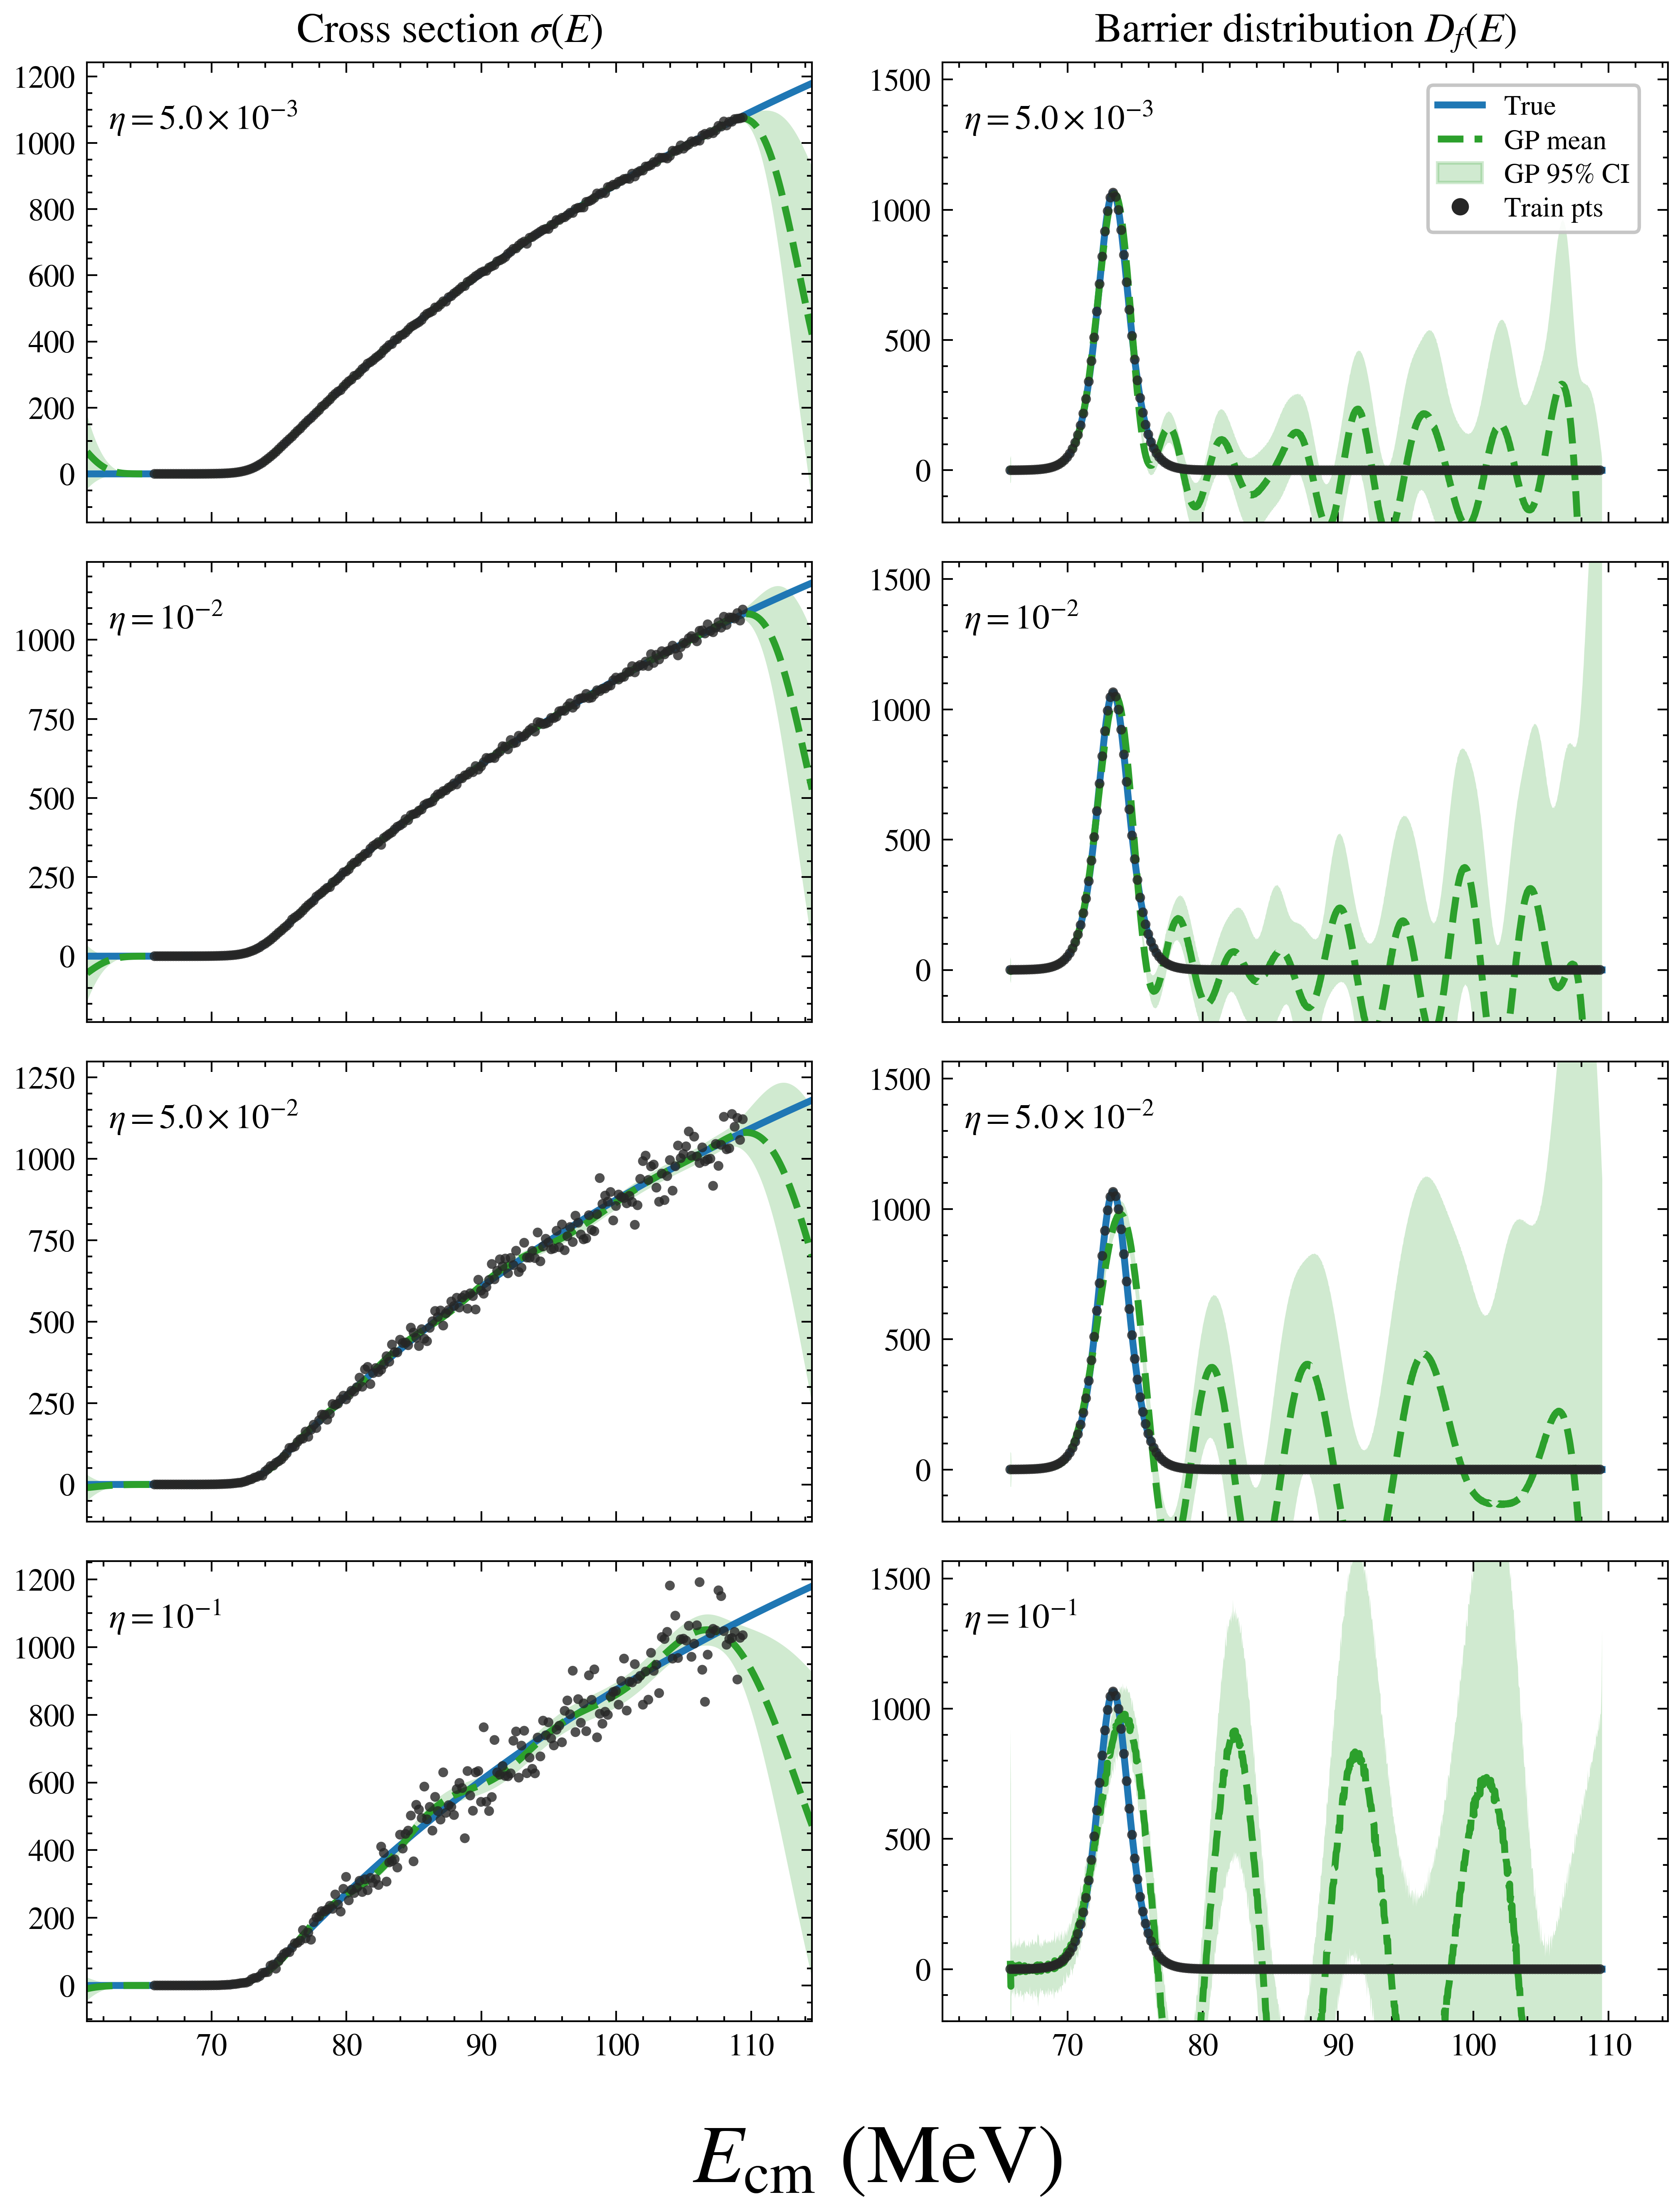

In [85]:
# Legacy individual noise-kernel exports are now one combined LaTeX-ready figure.
plot_sigma_barrier_grid(
    results_noise,
    "../plots/gp_sigma_and_barrier_grid_noise.png",
   # suptitle="RBF kernel with fitted white-noise term",
)


### Experiment 3: Effect of Resolution at different noise ratio

In [74]:
factors = [5, 10, 20, 40]
rng     = np.random.default_rng()
#stop = np.argmin(np.abs(E_fine - 100.0))
for f in factors:
    # 1) coarsen
    E_tr       = E_fine[::f]
    E_dist     = np.arange(E_tr[0] - 5, E_tr[-1] + 5, 0.2)
    y_tr       = sigma_mean[::f]
    var_tr     = (0.1 * y_tr)**2
    y_tr_noisy = y_tr + rng.normal(0, np.sqrt(var_tr))
    var_tr_1e_2     = (0.01 * y_tr)**2
    y_tr_noisy_1e_2 = y_tr + rng.normal(0, np.sqrt(var_tr_1e_2))

    tag = str(f)
    if save_data:
        np.save(f"../data/E_tr_{tag}.npy",          E_tr)
        np.save(f"../data/E_dist_{tag}.npy",        E_dist)
        np.save(f"../data/y_tr_noisy_{tag}_1e-1.npy",    y_tr_noisy)
        np.save(f"../data/y_tr_noisy_{tag}_1e-2.npy",    y_tr_noisy_1e_2)
        np.save(f"../data/var_tr_{tag}_1e-1.npy",        var_tr)
        np.save(f"../data/var_tr_{tag}_1e-2.npy",        var_tr_1e_2)


### Experiment 3: 
- Noise Ratio: $\eta$ = $10^{-1}$

In [75]:
# LOAD AND TRAIN
factors = [5,10,20,40]
barrier_results = {}

log = True
for f in factors:
    tag = str(f)
    E_tr       = np.load(f"../data/E_tr_{tag}.npy")
    E_dist     = np.load(f"../data/E_dist_{tag}.npy")
    y_tr_noisy = np.load(f"../data/y_tr_noisy_{tag}_1e-1.npy")
    var_tr     = np.load(f"../data/var_tr_{tag}_1e-1.npy")

    gp = train_gp(E_tr, y_tr_noisy, var_tr, n_restarts=gp_n_restarts, log=log)
    samples = np.exp(gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)) if log else gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)
    barrier_results[f] = {
        "E_tr": E_tr,
        "samples": samples,
        "E_dist": E_dist
    }


140597.09852555592
133682.3510657167
136718.0520194281
138353.35994334033


In [76]:
# The eta=10^-1 resolution results are plotted together with eta=10^-2 after both fits are available.


### Experiment 3: 
- Noise Ratio: $\eta$ = $10^{-2}$

In [77]:
factors = [5,10,20,40]
barrier_results_2 = {}

log = True
for f in factors:
    tag = str(f)
    E_tr       = np.load(f"../data/E_tr_{tag}.npy")
    E_dist     = np.load(f"../data/E_dist_{tag}.npy")
    y_tr_noisy = np.load(f"../data/y_tr_noisy_{tag}_1e-2.npy")
    var_tr     = np.load(f"../data/var_tr_{tag}_1e-2.npy")

    gp = train_gp(E_tr, y_tr_noisy, var_tr, n_restarts=gp_n_restarts, log=log)
    samples = np.exp(gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)) if log else gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)
    barrier_results_2[f] = {
        "E_tr": E_tr,
        "E_dist": E_dist,
        "samples": samples
    }


131671.17540651982


132319.04851077564
132838.12095675402
130999.58326932442


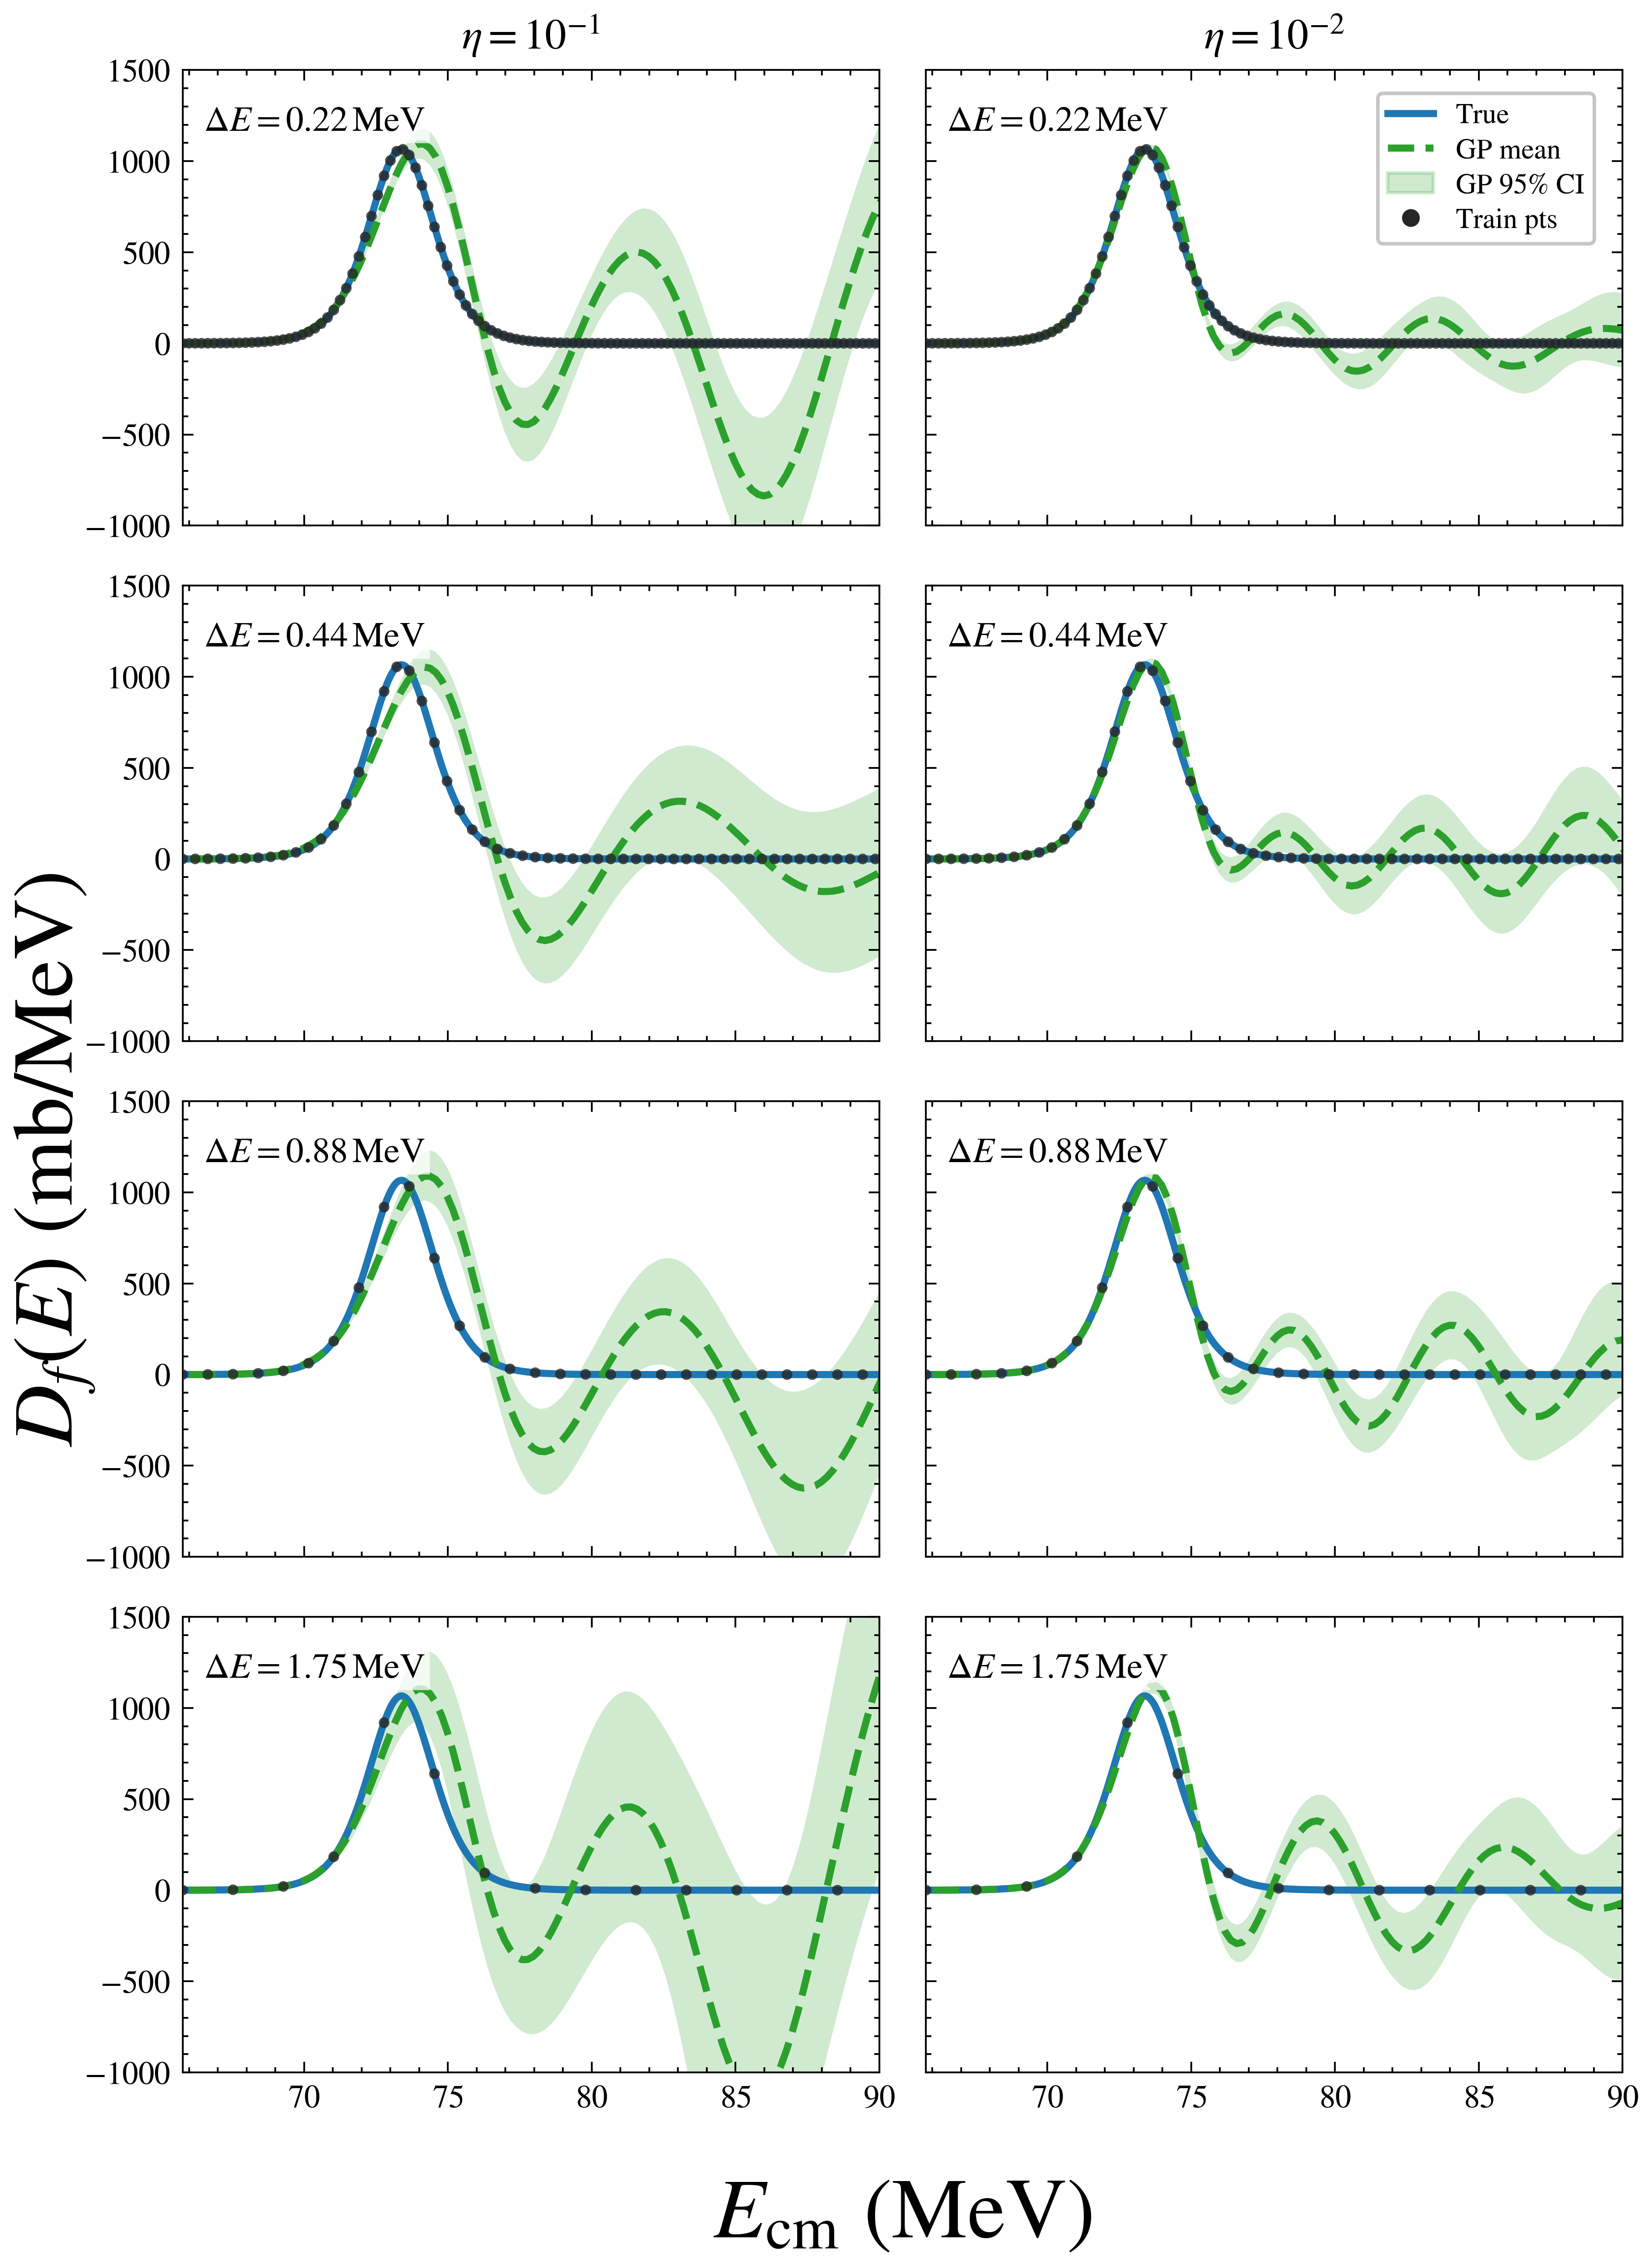

In [78]:
plot_barrier_comparison_grid(
    [
        (rf"$\eta = 10^{{-1}}$", barrier_results, None),
        (rf"$\eta = 10^{{-2}}$", barrier_results_2, None),
    ],
    "../plots/gp_barrier_coarse_grid_noise_comparison.png",
    row_keys=factors,
    panel_label_fn=lambda f, data: rf"$\Delta E = {data['E_tr'][1] - data['E_tr'][0]:.2f}\,\mathrm{{MeV}}$",
    suptitle=None,
)


### Experiment 4: Irregularity of Data, Average spacing of 0.5 MeV

In [79]:
cv_values    = [0.0, 0.25, 0.5, 0.75]
mean_spacing = 0.5   # MeV
rng          = np.random.default_rng(0)

# find your limits from existing E_fine
stop_idx = -1#np.argmin(np.abs(E_fine - 80.0))
E_min, E_max = E_fine[0], E_fine[stop_idx]

# evaluation grid — save once
E_dist = np.arange(E_min - 5, E_max + 5, 0.2)
if save_data:
    np.save("../data/E_dist_cv.npy", E_dist)

for cv in cv_values:
    std_sp = mean_spacing * cv
    N      = int((E_max - E_min) / mean_spacing) + 5

    # 1) build irregular E_tr
    dE_sim = np.random.normal(mean_spacing, std_sp, size=N)
    dE_sim = np.clip(dE_sim, 1e-3, None)
    E_tr   = E_min + np.cumsum(dE_sim)
    E_tr   = E_tr[E_tr <= E_max]

    # 2) interpolate and corrupt
    y_tr       = np.interp(E_tr, E_fine[:stop_idx], sigma_mean[:stop_idx])
    var_tr     = (0.01 * y_tr)**2
    y_tr_noisy = y_tr + rng.normal(0, np.sqrt(var_tr), size=y_tr.shape)

    tag = f"{cv:.2f}"
    if save_data:
        np.save(f"../data/E_tr_cv_{tag}.npy",       E_tr)
        np.save(f"../data/y_tr_cv_{tag}.npy",       y_tr)
        np.save(f"../data/var_tr_cv_{tag}.npy",     var_tr)
        np.save(f"../data/y_tr_noisy_cv_{tag}.npy", y_tr_noisy)



In [80]:
cv_values = [0.0, 0.25, 0.5, 0.75]
mean_spacing = 0.5 # 0.5   # MeV
barrier_results_cv = {}

log=True
for cv in cv_values:
    tag       = f"{cv:.2f}"
    E_tr      = np.load(f"../data/E_tr_cv_{tag}.npy")
    y_tr_noisy= np.load(f"../data/y_tr_noisy_cv_{tag}.npy")
    var_tr    = np.load(f"../data/var_tr_cv_{tag}.npy")

    gp = train_gp(E_tr, y_tr_noisy, var_tr, n_restarts=gp_n_restarts, log=log)
    samples = np.exp(gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)) if log else gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)

    barrier_results_cv[cv] = {
        "E_tr":    E_tr,
        "y_tr":    y_tr_noisy,
        "var_tr":  var_tr,
        "samples": samples
    }

E_dist_cv_05 = E_dist.copy()


131948.07494758777
135795.49309768138


126115.59680334012
127343.31732717894


In [81]:
# The 0.5 MeV irregularity results are plotted together with 1.0 MeV after both fits are available.


### Experiment 4: Average Spacing of 1 MeV

In [82]:
cv_values    = [0.0, 0.25, 0.5, 0.75]
mean_spacing = 1.0   # MeV
rng          = np.random.default_rng(0)

# find your limits from existing E_fine
stop_idx = -1#np.argmin(np.abs(E_fine - 80.0))
E_min, E_max = E_fine[0], E_fine[stop_idx]

# evaluation grid — save once
E_dist = np.arange(E_min - 5, E_max + 5, 0.2)
if save_data:
    np.save("../data/E_dist_cv_1MEV.npy", E_dist)

for cv in cv_values:
    std_sp = mean_spacing * cv
    N      = int((E_max - E_min) / mean_spacing) + 5

    # 1) build irregular E_tr
    dE_sim = np.random.normal(mean_spacing, std_sp, size=N)
    dE_sim = np.clip(dE_sim, 1e-3, None)
    E_tr   = E_min + np.cumsum(dE_sim)
    E_tr   = E_tr[E_tr <= E_max]

    # 2) interpolate and corrupt
    y_tr       = np.interp(E_tr, E_fine[:stop_idx], sigma_mean[:stop_idx])
    var_tr     = (0.01 * y_tr)**2
    y_tr_noisy = y_tr + rng.normal(0, np.sqrt(var_tr), size=y_tr.shape)

    tag = f"{cv:.2f}"
    if save_data:
        np.save(f"../data/E_tr_cv_{tag}_1MEV.npy",       E_tr)
        np.save(f"../data/y_tr_cv_{tag}_1MEV.npy",       y_tr)
        np.save(f"../data/var_tr_cv_{tag}_1MEV.npy",     var_tr)
        np.save(f"../data/y_tr_noisy_cv_{tag}_1MEV.npy", y_tr_noisy)

In [83]:
cv_values = [0.0, 0.25, 0.5, 0.75]
mean_spacing = 1.0 # 0.5   # MeV
barrier_results_cv_2 = {}

log=True
for cv in cv_values:
    tag       = f"{cv:.2f}"
    E_tr      = np.load(f"../data/E_tr_cv_{tag}_1MEV.npy")
    y_tr_noisy= np.load(f"../data/y_tr_noisy_cv_{tag}_1MEV.npy")
    var_tr    = np.load(f"../data/var_tr_cv_{tag}_1MEV.npy")

    gp = train_gp(E_tr, y_tr_noisy, var_tr, n_restarts=gp_n_restarts, log=log)
    samples = np.exp(gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)) if log else gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)

    barrier_results_cv_2[cv] = {
        "E_tr":    E_tr,
        "y_tr":    y_tr_noisy,
        "var_tr":  var_tr,
        "samples": samples
    }

E_dist_cv_10 = E_dist.copy()


130731.25821889406
137111.0884244912
121603.49531154831
143786.28383837265


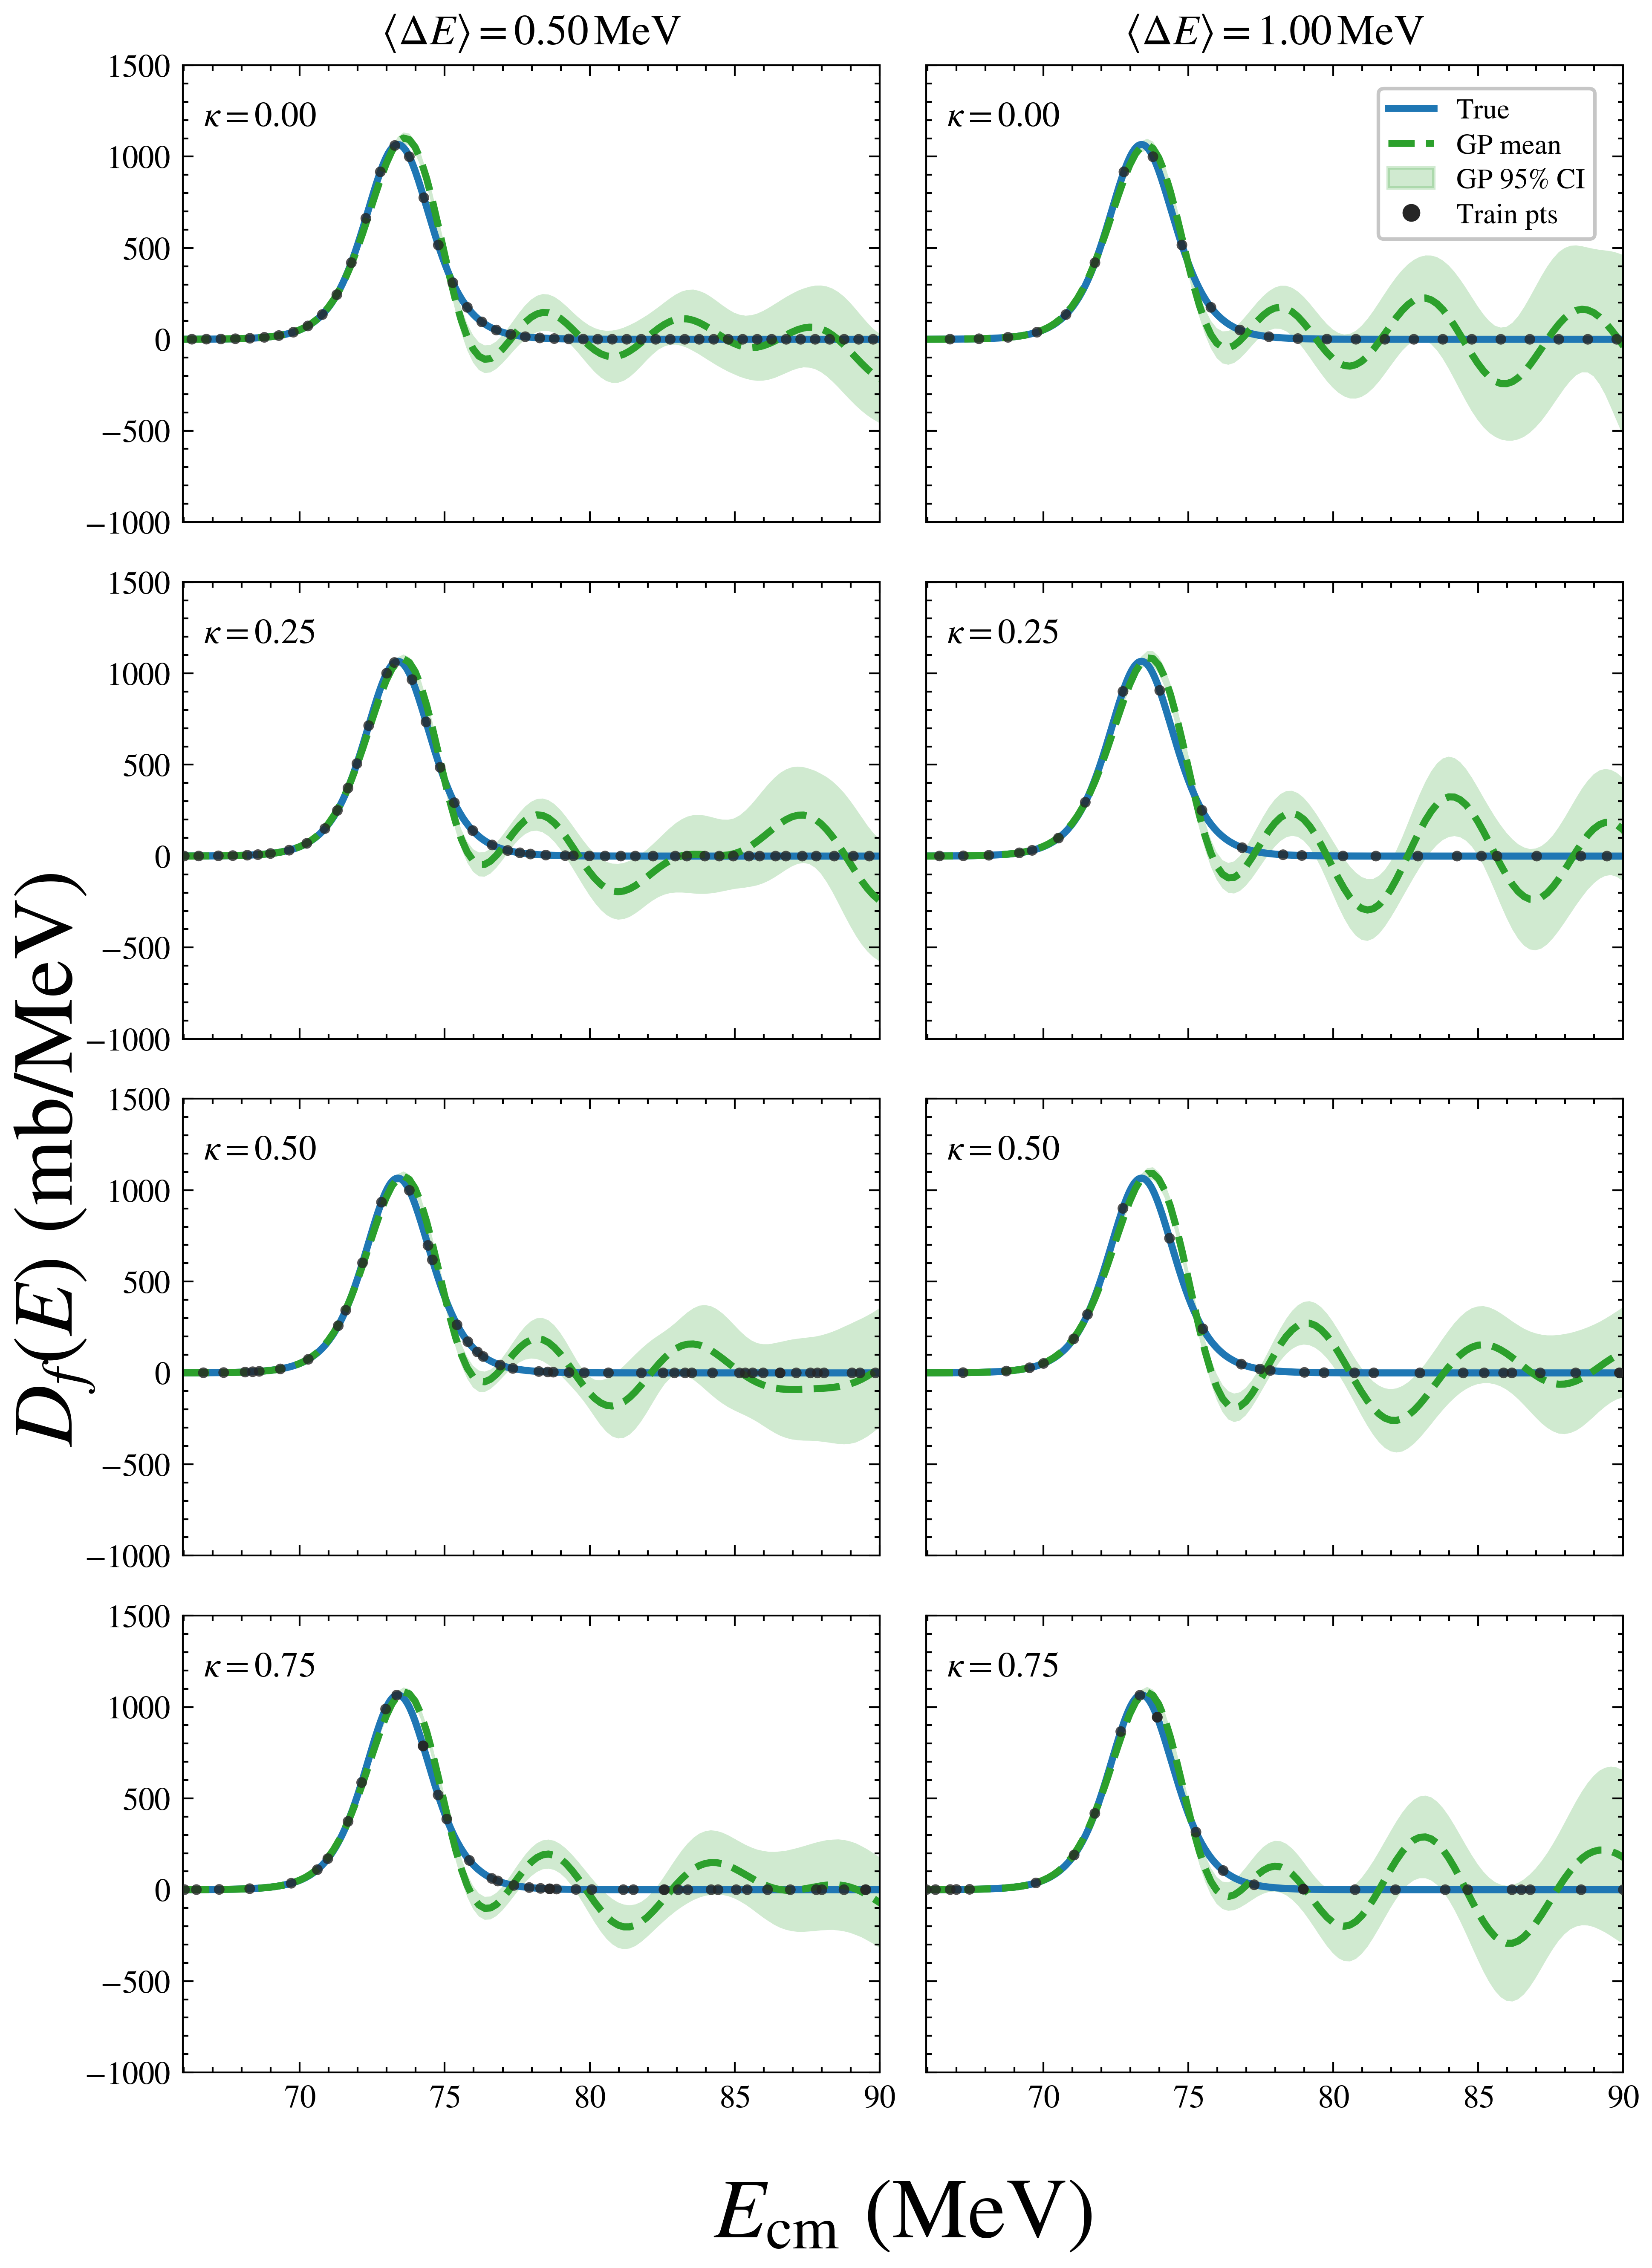

In [84]:
plot_barrier_comparison_grid(
    [
        (rf"$\langle\Delta E\rangle = 0.50\,\mathrm{{MeV}}$", barrier_results_cv, lambda cv, data: E_dist_cv_05),
        (rf"$\langle\Delta E\rangle = 1.00\,\mathrm{{MeV}}$", barrier_results_cv_2, lambda cv, data: E_dist_cv_10),
    ],
    "../plots/gp_barrier_cv_grid_spacing_comparison.png",
    row_keys=cv_values,
    panel_label_fn=lambda cv, data: rf"$\kappa = {cv:.2f}$",
    suptitle=None,
)


### Big Picture Conclusions: 

- The GP begins to miss the barrier when the estimated error to sigma ratio is between order of magnitudes 0.01 and 0.1. 
- In general, adding a White Noise kernel has little to no effect when included as the optimizer tries to minimize the noise level. 

- At characteristic resolutions of realistic experimental data, one can actually have very sparse data if the noise ratio is around $10^{-2}$

- We quantify irregularity of our data by the CV of the step sizes. Again, so long as noise ratio is low, one can use very irregular data and still capture the height and location of the barrier well. 